<a href="https://colab.research.google.com/github/kritarthteli/AI-LAB/blob/main/Week10_AlphaBetaPrunning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ALPHA-BETA PRUNING (Simple Number Input)
Tip: Enter counts separated by spaces. Example for your slide:
  Level 0 : 3
  Level 1 : 2 2 2
  Level 2 : 2 1 2 1 1 1
  Level 3 : 2 3 1 1 2 1 1 2 1
  Leaves  : 5 6 7 4 5 3 6 6 9 7 5 9 8 6

Level 0 - Enter child count for each of the 1 node(s): 3
Is the next level the LEAF values? (y/n): n
Level 1 - Enter child count for each of the 3 node(s): 2 2 2
Is the next level the LEAF values? (y/n): n
Level 2 - Enter child count for each of the 6 node(s): 2 1 2 1 1 2
Is the next level the LEAF values? (y/n): n
Level 3 - Enter child count for each of the 9 node(s): 2 3 1 1 2 1 1 2 1
Is the next level the LEAF values? (y/n): y

Enter all 14 leaf values (left to right): 5 6 7 4 5 3 6 6 9 7 5 9 8 6
Enter root mode (MAX/MIN): MAX

--- SEARCH PROCESS ---
Visited: Root.1.1.1.1 = 5
Visited: Root.1.1.1.2 = 6
Visited: Root.1.1.2.1 = 7
Visited: Root.1.1.2.2 = 4
Pruned at: Root.1.1.2 (Skipped leaf nodes: 1)
Visited: Root.1.2.1.1 = 3
Visited: Root.2.1.1.1 = 6
Visited

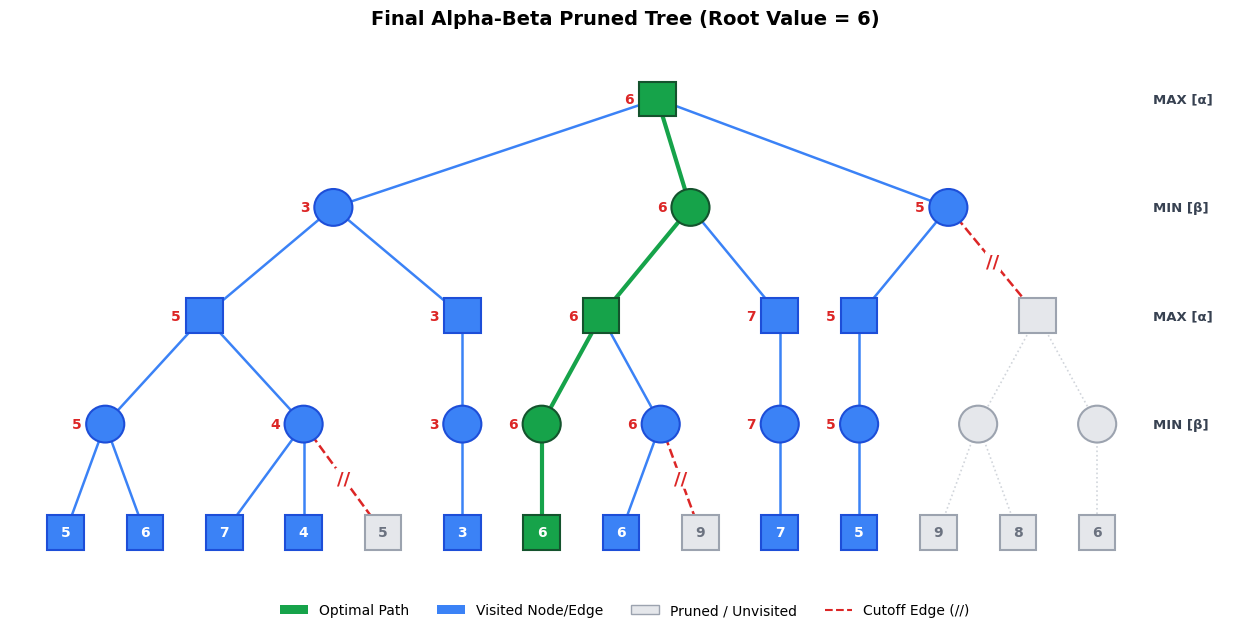

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# ==========================================
# 1. SIMPLE LEVEL-BY-LEVEL INPUT
# ==========================================
print("ALPHA-BETA PRUNING (Simple Number Input)")
print("Tip: Enter counts separated by spaces. Example for your slide:")
print("  Level 0 : 3")
print("  Level 1 : 2 2 2")
print("  Level 2 : 2 1 2 1 1 1")
print("  Level 3 : 2 3 1 1 2 1 1 2 1")
print("  Leaves  : 5 6 7 4 5 3 6 6 9 7 5 9 8 6\n")

# Build tree layer by layer using child counts
levels = [[]]  # Start with 1 root placeholder
lvl = 0

while True:
    expected_nodes = 1 if lvl == 0 else sum(levels[-1])
    raw = input(f"Level {lvl} - Enter child count for each of the {expected_nodes} node(s): ").strip()
    counts = list(map(int, raw.split()))

    if len(counts) != expected_nodes or any(c < 1 for c in counts):
        print(f"  -> Please enter exactly {expected_nodes} positive number(s).")
        continue

    if lvl == 0:
        levels[0] = counts
    else:
        levels.append(counts)

    more = input("Is the next level the LEAF values? (y/n): ").strip().lower()
    if more == 'y':
        break
    lvl += 1

total_leaves = sum(levels[-1])
while True:
    leaf_raw = input(f"\nEnter all {total_leaves} leaf values (left to right): ").strip()
    leaves = list(map(int, leaf_raw.split()))
    if len(leaves) == total_leaves:
        break
    print(f"  -> Expected {total_leaves} numbers, got {len(leaves)}. Try again.")

root_mode = input("Enter root mode (MAX/MIN): ").strip().upper()
if root_mode not in ("MAX", "MIN"):
    raise ValueError("Enter MAX or MIN")
root_is_max = (root_mode == "MAX")

# Convert level counts into nested list structure
current_layer = leaves
for counts in reversed(levels):
    next_layer = []
    idx = 0
    for c in counts:
        next_layer.append(current_layer[idx : idx + c])
        idx += c
    current_layer = next_layer

tree = current_layer[0]

# ==========================================
# 2. ALPHA-BETA SEARCH & RECORDING
# ==========================================
def count_leaves(node):
    if isinstance(node, (int, float)):
        return 1
    return sum(count_leaves(child) for child in node)

visited = 0
pruned = 0
node_values = {}
visited_edges = set()
pruned_edges = set()

def alpha_beta(node, alpha, beta, is_max, path="Root"):
    global visited, pruned

    if isinstance(node, (int, float)):
        visited += 1
        node_values[path] = node
        print(f"Visited: {path} = {node}")
        return node, [path]

    best_path = []

    if is_max:
        value = float('-inf')
        for i, child in enumerate(node):
            child_path = f"{path}.{i+1}"
            visited_edges.add((path, child_path))

            child_val, c_path = alpha_beta(child, alpha, beta, False, child_path)
            if child_val > value:
                value = child_val
                best_path = [path] + c_path

            alpha = max(alpha, value)
            node_values[path] = value

            if alpha >= beta:
                remaining = node[i+1:]
                if remaining:
                    skipped = sum(count_leaves(x) for x in remaining)
                    pruned += skipped
                    print(f"Pruned at: {path} (Skipped leaf nodes: {skipped})")
                    for rem_idx in range(i + 1, len(node)):
                        pruned_edges.add((path, f"{path}.{rem_idx+1}"))
                break
        return value, best_path

    else:
        value = float('inf')
        for i, child in enumerate(node):
            child_path = f"{path}.{i+1}"
            visited_edges.add((path, child_path))

            child_val, c_path = alpha_beta(child, alpha, beta, True, child_path)
            if child_val < value:
                value = child_val
                best_path = [path] + c_path

            beta = min(beta, value)
            node_values[path] = value

            if alpha >= beta:
                remaining = node[i+1:]
                if remaining:
                    skipped = sum(count_leaves(x) for x in remaining)
                    pruned += skipped
                    print(f"Pruned at: {path} (Skipped leaf nodes: {skipped})")
                    for rem_idx in range(i + 1, len(node)):
                        pruned_edges.add((path, f"{path}.{rem_idx+1}"))
                break
        return value, best_path

print("\n--- SEARCH PROCESS ---")
result, optimal_path = alpha_beta(tree, float('-inf'), float('inf'), root_is_max)

print("\n--- FINAL RESULT ---")
print("Optimal Value     :", result)
print("Optimal Path      :", " -> ".join(optimal_path))
print("Visited Leaf Nodes:", visited)
print("Pruned Leaf Nodes :", pruned)
print("Total Leaf Nodes  :", visited + pruned)

# ==========================================
# 3. BUILD & DRAW FINAL TREE GRAPH
# ==========================================
def get_depth(node):
    if isinstance(node, (int, float)):
        return 0
    return 1 + max(get_depth(c) for c in node)

max_depth = get_depth(tree)
coords = {}
node_info = {}
all_edges = []
leaf_x = 0

def layout_tree(node, level=0, is_max=root_is_max, path="Root"):
    global leaf_x
    is_leaf = isinstance(node, (int, float))
    ntype = "LEAF" if is_leaf else ("MAX" if is_max else "MIN")
    y = max_depth - level

    if is_leaf:
        x = leaf_x * 10.0
        leaf_x += 1
        coords[path] = (x, y)
        node_info[path] = {"type": ntype, "val": node}
    else:
        child_xs = []
        for i, child in enumerate(node):
            c_path = f"{path}.{i+1}"
            all_edges.append((path, c_path))
            cx = layout_tree(child, level + 1, not is_max, c_path)
            child_xs.append(cx)
        x = sum(child_xs) / len(child_xs)
        coords[path] = (x, y)
        node_info[path] = {"type": ntype, "val": node_values.get(path)}
    return x

layout_tree(tree)

optimal_set = set(optimal_path)
optimal_edges = set(zip(optimal_path[:-1], optimal_path[1:]))
max_x = max((leaf_x - 1) * 10.0, 10.0)

fig, ax = plt.subplots(figsize=(max(10, leaf_x * 0.9), max(6, max_depth * 1.6)))
ax.set_title(f"Final Alpha-Beta Pruned Tree (Root Value = {result})", fontsize=14, fontweight="bold", pad=15)

# Draw Edges
for u, v in all_edges:
    x1, y1 = coords[u]
    x2, y2 = coords[v]
    if (u, v) in optimal_edges:
        ax.plot([x1, x2], [y1, y2], color="#16a34a", linewidth=3.0, zorder=3)
    elif (u, v) in pruned_edges:
        ax.plot([x1, x2], [y1, y2], color="#dc2626", linestyle="--", linewidth=1.8, zorder=2)
        mx, my = (x1 + x2) / 2, (y1 + y2) / 2
        ax.text(mx, my, "//", color="#dc2626", fontsize=13, fontweight="bold",
                ha="center", va="center", bbox=dict(boxstyle="round,pad=0.08", fc="white", ec="none"))
    elif (u, v) in visited_edges:
        ax.plot([x1, x2], [y1, y2], color="#3b82f6", linewidth=1.8, zorder=2)
    else:
        ax.plot([x1, x2], [y1, y2], color="#d1d5db", linestyle=":", linewidth=1.2, zorder=1)

# Draw Nodes
for path, (x, y) in coords.items():
    ntype = node_info[path]["type"]
    val = node_info[path]["val"]
    is_visited = (path in node_values)

    if path in optimal_set:
        fc, ec = "#16a34a", "#14532d"
    elif is_visited:
        fc, ec = "#3b82f6", "#1d4ed8"
    else:
        fc, ec = "#e5e7eb", "#9ca3af"

    if ntype in ("MAX", "LEAF"):
        rect = patches.Rectangle((x - 2.3, y - 0.16), 4.6, 0.32,
                                 facecolor=fc, edgecolor=ec, linewidth=1.5, zorder=4)
        ax.add_patch(rect)
    else:
        circle = patches.Ellipse((x, y), width=4.8, height=0.34,
                                 facecolor=fc, edgecolor=ec, linewidth=1.5, zorder=4)
        ax.add_patch(circle)

    if ntype == "LEAF":
        txt_col = "white" if is_visited else "#6b7280"
        ax.text(x, y, str(val), color=txt_col, fontsize=10, fontweight="bold", ha="center", va="center", zorder=5)
    elif val is not None:
        ax.text(x - 3.0, y, str(val), color="#dc2626", fontsize=10, fontweight="bold", ha="right", va="center", zorder=5)

# Side Level Labels (MAX / MIN)
for lvl in range(max_depth):
    is_lvl_max = root_is_max if (lvl % 2 == 0) else (not root_is_max)
    lbl = "MAX [α]" if is_lvl_max else "MIN [β]"
    ax.text(max_x + 7, max_depth - lvl, lbl, fontsize=9.5, fontweight="bold", color="#374151", va="center")

legend_items = [
    patches.Patch(facecolor="#16a34a", label="Optimal Path"),
    patches.Patch(facecolor="#3b82f6", label="Visited Node/Edge"),
    patches.Patch(facecolor="#e5e7eb", edgecolor="#9ca3af", label="Pruned / Unvisited"),
    plt.Line2D([], [], color="#dc2626", linestyle="--", label="Cutoff Edge (//)")
]
ax.legend(handles=legend_items, loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=4, frameon=False)

ax.set_xlim(-7, max_x + 18)
ax.set_ylim(-0.5, max_depth + 0.5)
ax.axis("off")
plt.tight_layout()
plt.show()